In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

Загрузим наши файлы

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving test.csv to test (1).csv


In [ ]:
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

In [ ]:
df_train.shape
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 595212 entries, 0 to 595211
Data columns (total 59 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              595212 non-null  int64  
 1   target          595212 non-null  int64  
 2   ps_ind_01       595212 non-null  int64  
 3   ps_ind_02_cat   595212 non-null  int64  
 4   ps_ind_03       595212 non-null  int64  
 5   ps_ind_04_cat   595212 non-null  int64  
 6   ps_ind_05_cat   595212 non-null  int64  
 7   ps_ind_06_bin   595212 non-null  int64  
 8   ps_ind_07_bin   595212 non-null  int64  
 9   ps_ind_08_bin   595212 non-null  int64  
 10  ps_ind_09_bin   595212 non-null  int64  
 11  ps_ind_10_bin   595212 non-null  int64  
 12  ps_ind_11_bin   595212 non-null  int64  
 13  ps_ind_12_bin   595212 non-null  int64  
 14  ps_ind_13_bin   595212 non-null  int64  
 15  ps_ind_14       595212 non-null  int64  
 16  ps_ind_15       595212 non-null  int64  
 17  ps_ind_16_

1. EDA

In [ ]:
df_train.head()

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0


In [ ]:
df_train.isnull().sum()


,0
id,0
target,0
ps_ind_01,0
ps_ind_02_cat,0
ps_ind_03,0
ps_ind_04_cat,0
ps_ind_05_cat,0
ps_ind_06_bin,0
ps_ind_07_bin,0
ps_ind_08_bin,0


In [ ]:
df_test.isnull().sum()

,0
id,0
ps_ind_01,0
ps_ind_02_cat,0
ps_ind_03,0
ps_ind_04_cat,0
ps_ind_05_cat,0
ps_ind_06_bin,0
ps_ind_07_bin,0
ps_ind_08_bin,0
ps_ind_09_bin,0


Пустых значений нет. А теперь посмотрим как распределены признаки:

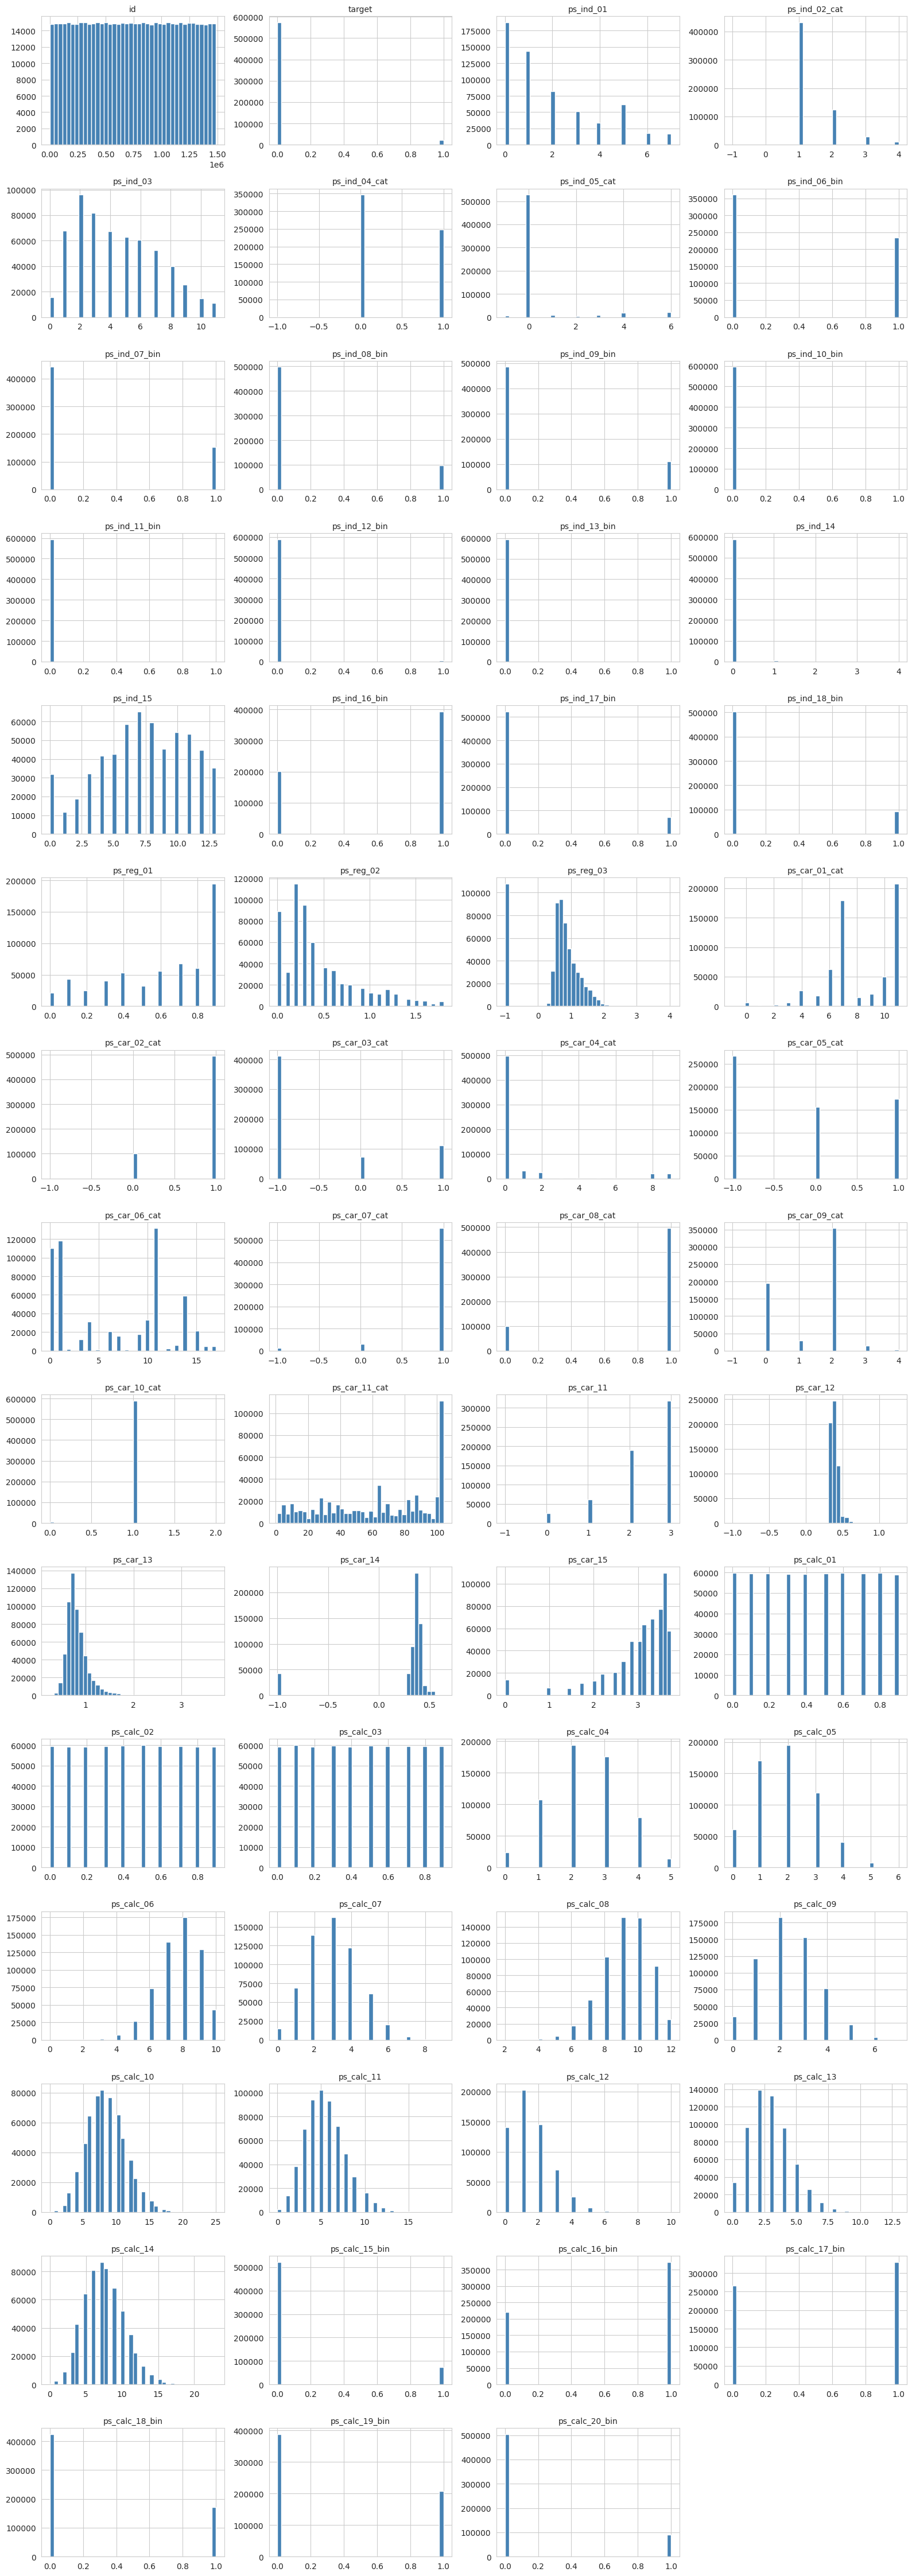

In [ ]:
numeric_cols = df_train.select_dtypes(include=np.number).columns.tolist()

n_cols = len(numeric_cols)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df_train[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

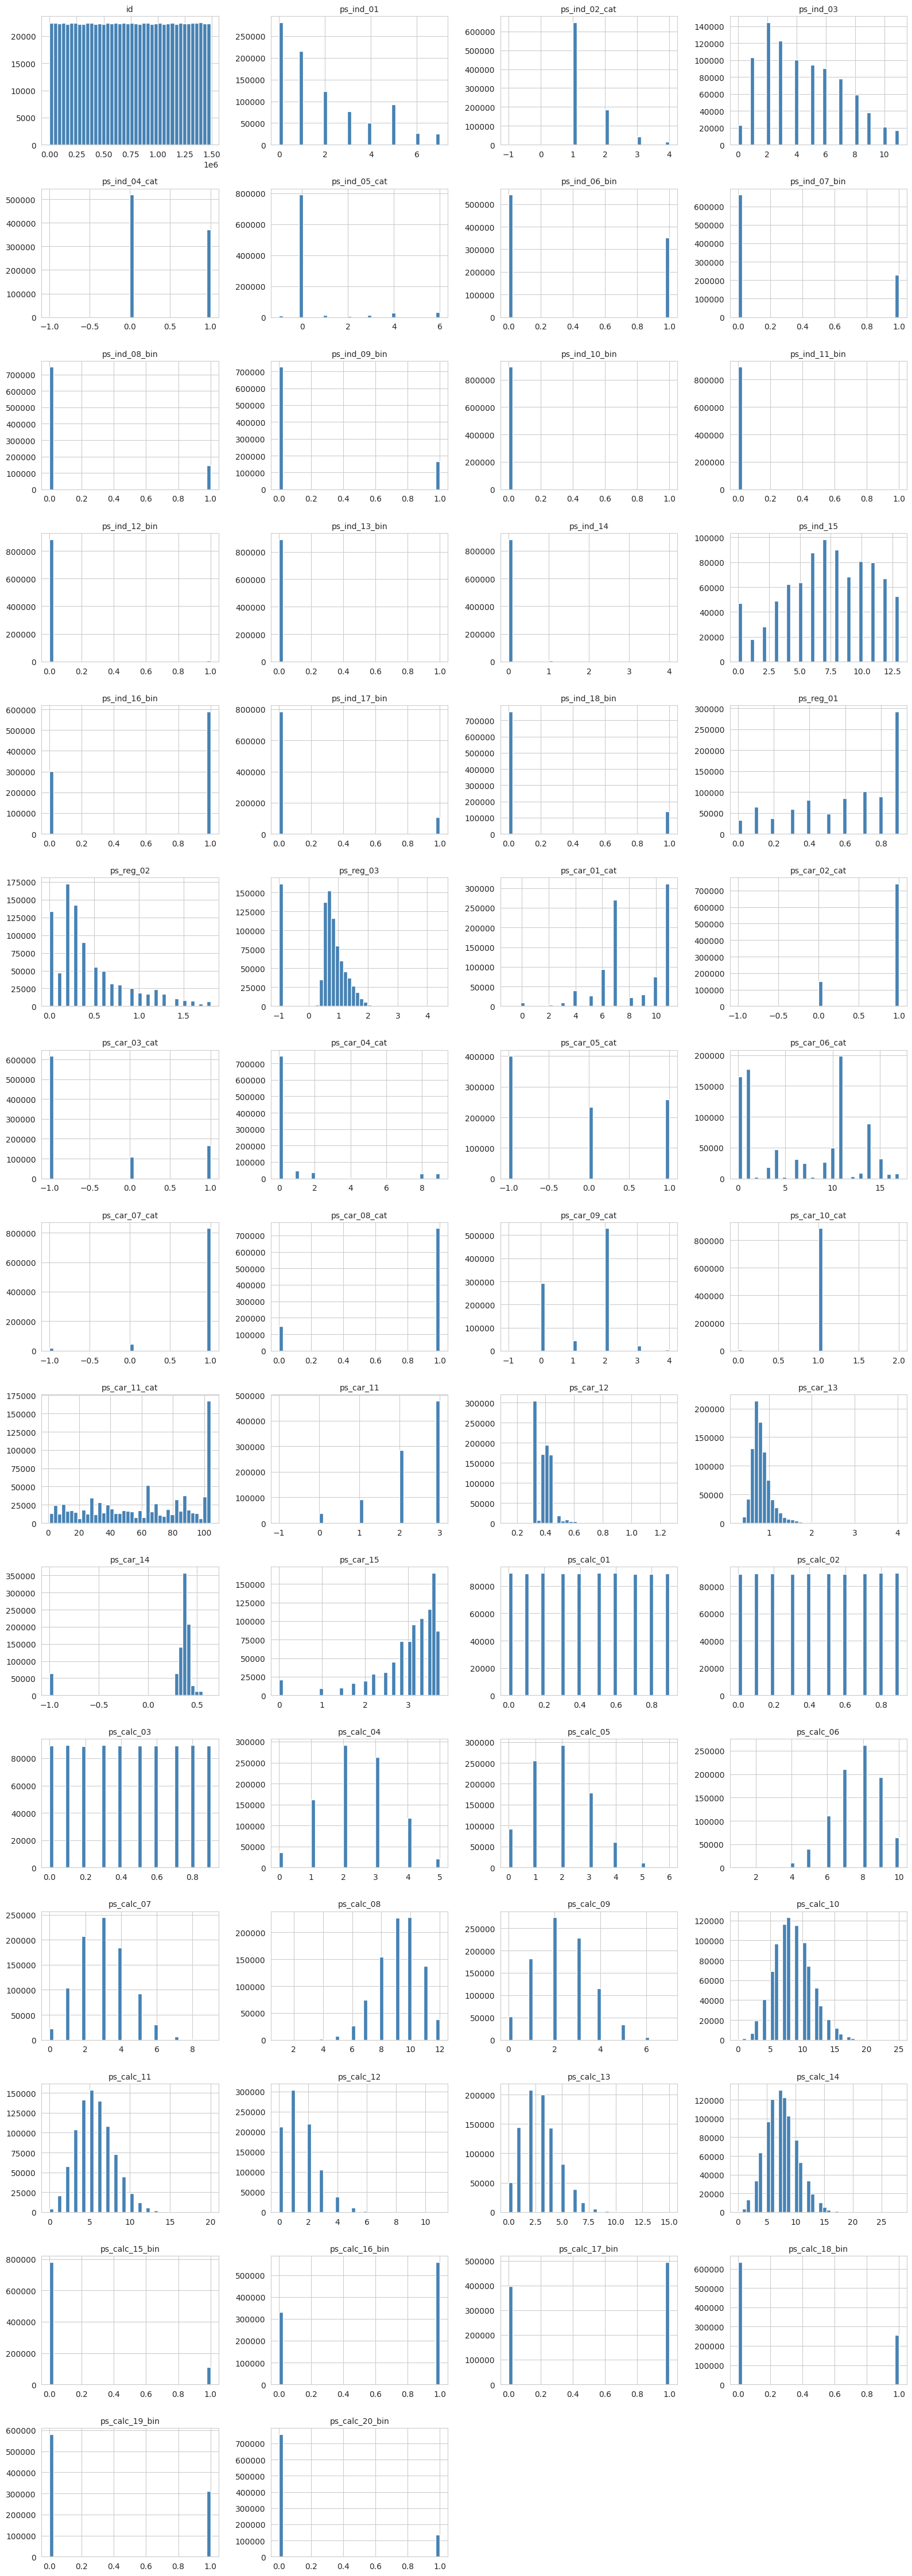

In [ ]:
numeric_cols2 = df_test.select_dtypes(include=np.number).columns.tolist()

n_cols = len(numeric_cols2)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols2):
    df_test[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(numeric_cols2), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Не в train, не в test  нет особых выбросов. Поэтому удалять ничего не будем.

**Корреляционная матрица**

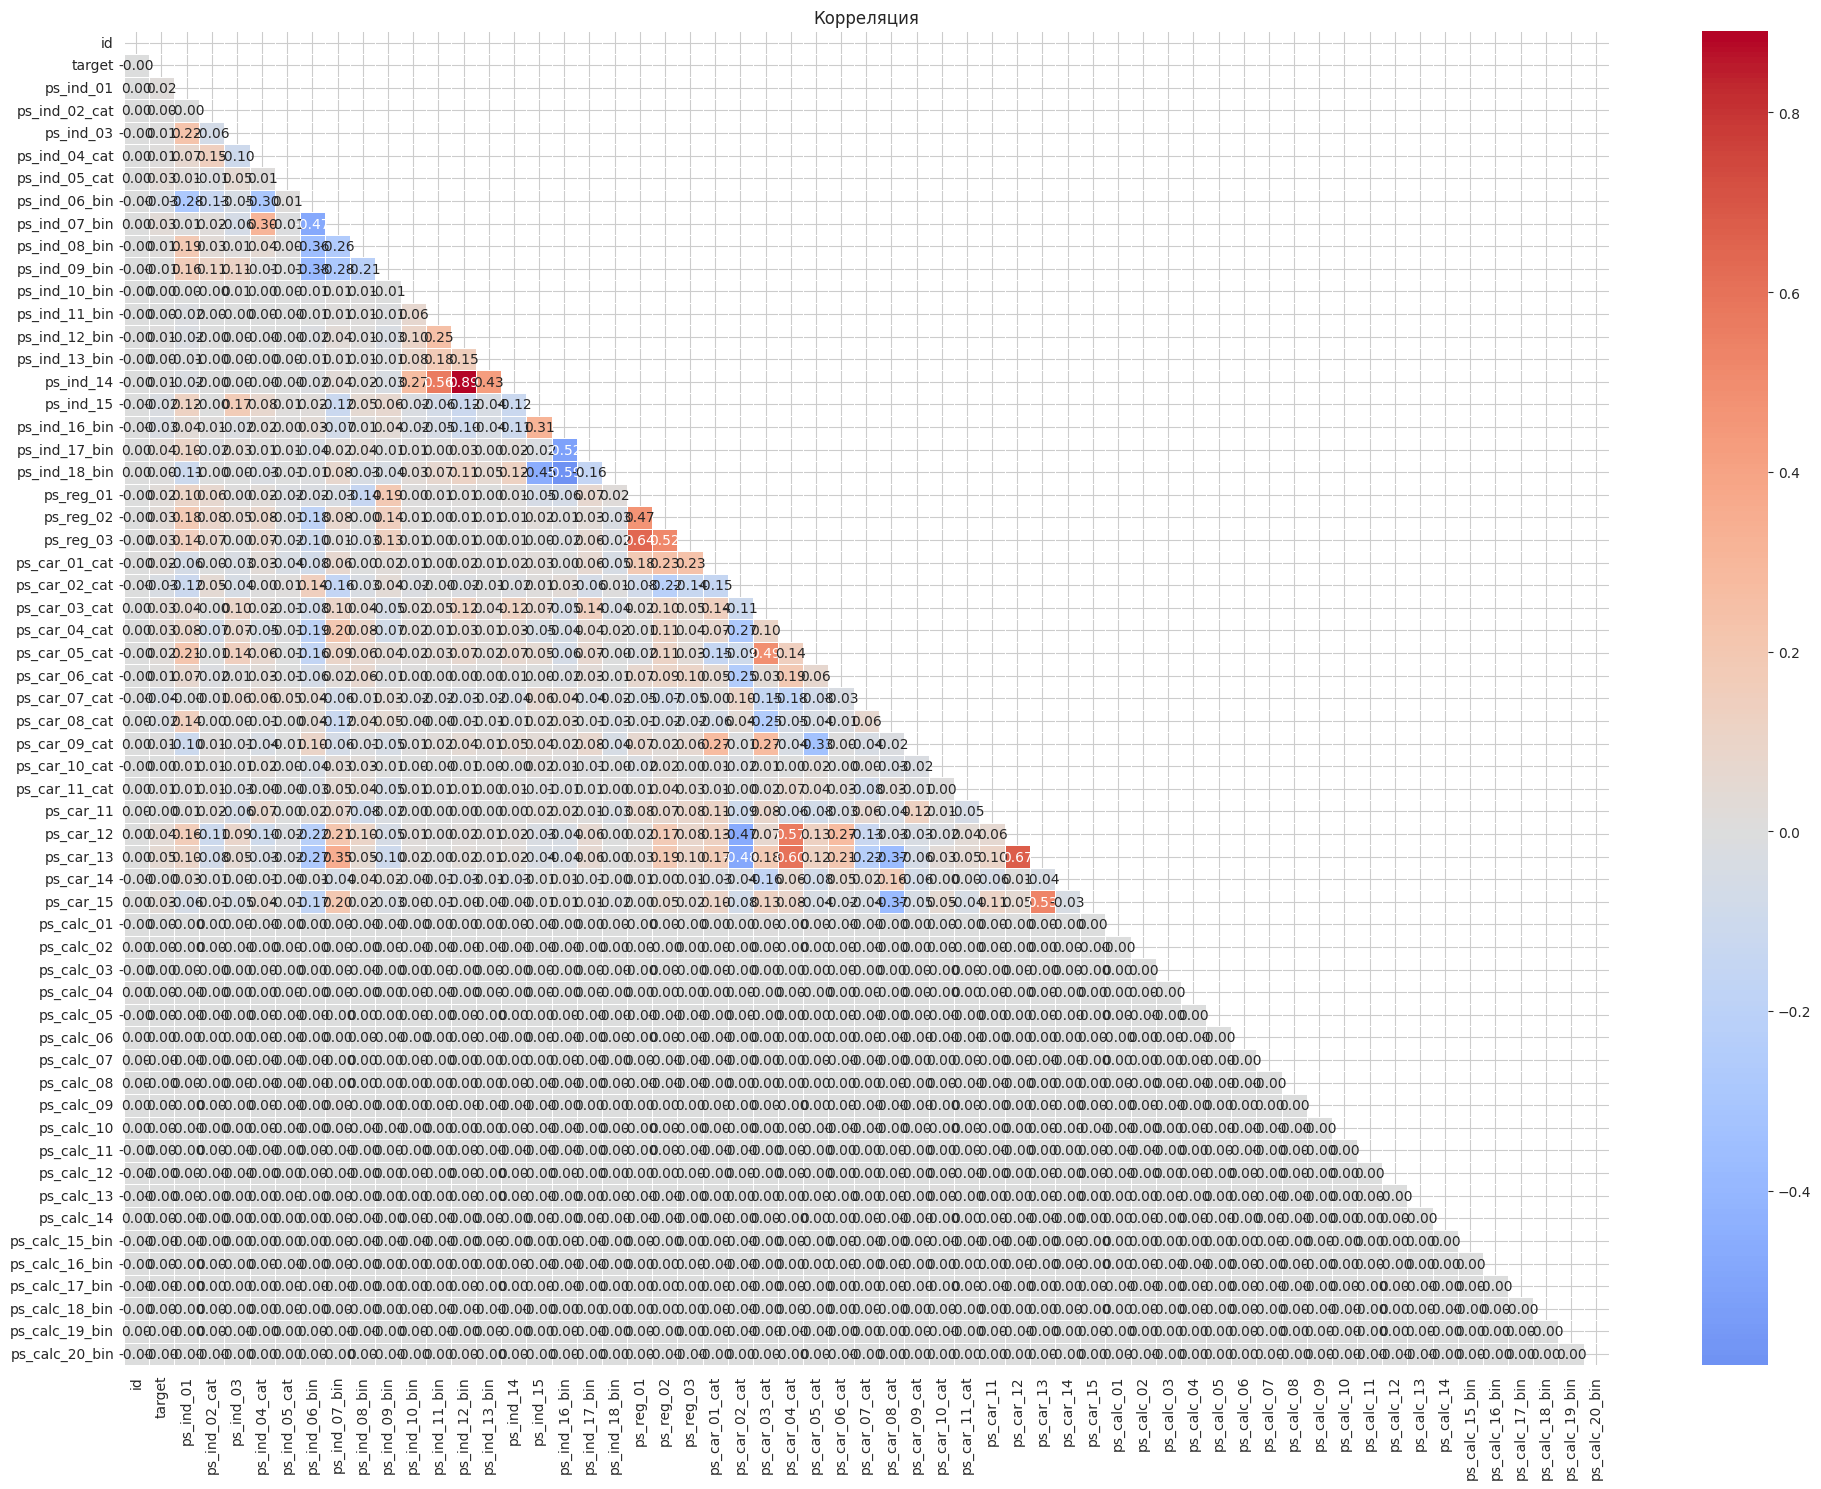

In [ ]:
plt.figure(figsize=(20, 15))
corr = df_train[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляция')
plt.tight_layout()
plt.show()

2. Подготовка данных

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, log_loss,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, ConfusionMatrixDisplay)

Y = 'target'

X_train_full = df_train.drop(columns=[Y]).copy()
y_train_full = df_train[Y].values

X_test = df_test.copy()

X_test = X_test[X_train_full.columns]

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2, random_state=1, stratify=y_train_full
)



Pipeline:

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

scaler = StandardScaler()

X_tr_sc   = X_tr.copy()
X_val_sc  = X_val.copy()

X_test_sc = X_test.copy()
cat_bin_cols = [c for c in X_tr.columns if c.endswith(('_bin', '_cat'))]
num_cols     = [c for c in X_tr.columns if c not in cat_bin_cols]
X_tr_sc[num_cols]   = scaler.fit_transform(X_tr[num_cols])
X_val_sc[num_cols]  = scaler.transform(X_val[num_cols])
X_test_sc[num_cols] = scaler.transform(X_test[num_cols])

**Классификация**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, log_loss,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)

log_reg_bin = LogisticRegression(max_iter=1000, random_state=1)
log_reg_bin.fit(X_tr_sc, y_tr)

y_pred_val  = log_reg_bin.predict(X_val_sc)
y_proba_val = log_reg_bin.predict_proba(X_val_sc)[:, 1]

auc = roc_auc_score(y_val, y_proba_val)
gini = 2 * auc - 1

frac_pos = np.mean(y_val)
gini_random = (1 - frac_pos) / 2
gini_norm = (gini - gini_random) / (1 - gini_random)

print(f"AUC          = {auc:.4f}")
print(f"Gini         = {gini:.4f}")
print(f"frac_pos     = {frac_pos:.4f}")
print(f"Gini_random  = {gini_random:.4f}")
print(f"Gini_norm    = {gini_norm:.4f}")

AUC          = 0.6214
Gini         = 0.2427
frac_pos     = 0.0364
Gini_random  = 0.4818
Gini_norm    = -0.4613


4. Бустинг

In [ ]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, scaled=False):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_te)[:, 1]
    else:
        y_proba = y_pred

    acc = accuracy_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred, average='macro')
    auc = roc_auc_score(y_te, y_proba)
    gini = 2 * auc - 1


    frac_pos = np.mean(y_te)
    gini_random = (1 - frac_pos) / 2
    gini_norm = (gini - gini_random) / (1 - gini_random) if gini_random < 1 else np.nan
    results[name] = {
        'accuracy': acc,
        'f1_macro': f1,
        'auc': auc,
        'gini': gini,
        'gini_norm': gini_norm
    }

    print(f'{name}: accuracy={acc:.4f}, F1-macro={f1:.4f}, AUC={auc:.4f}, Gini={gini:.4f}, Gini_norm={gini_norm:.4f}')
    return y_pred

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
RANDOM_STATE = 23

gb_sklearn = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=5,
                                         random_state=RANDOM_STATE)
y_pred_gb = evaluate_model('GradientBoosting', gb_sklearn, X_tr, X_val, y_tr, y_val )

KeyboardInterrupt: 

In [ ]:
import time
from xgboost import XGBClassifier

ratio = (y_tr == 0).sum() / (y_tr == 1).sum()

t0 = time.time()
xgb_top = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=ratio,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

y_pred_xgb_top = evaluate_model('XGBoost (Top-10)', xgb_top, X_tr_top, X_val_top, y_tr, y_val)
print(f' Время: {time.time()-t0:.1f} с')

          feature  importance
17  ps_ind_17_bin    0.069399
6   ps_ind_06_bin    0.057979
28  ps_car_07_cat    0.052791
24  ps_car_03_cat    0.044396
5   ps_ind_05_cat    0.041111
35      ps_car_13    0.040970
16  ps_ind_16_bin    0.033368
7   ps_ind_07_bin    0.027605
9   ps_ind_09_bin    0.022944
3       ps_ind_03    0.022321
XGBoost (Top-10): accuracy=0.6736, F1-macro=0.4511, AUC=0.6309, Gini=0.2618, Gini_norm=-0.4245
 Время: 45.1 с


Попробуем XGBoost

In [ ]:
import time

ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"Коэффициент дисбаланса: {ratio:.2f}")

try:
    from xgboost import XGBClassifier
    t0 = time.time()
    xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, scale_pos_weight=ratio,
                         random_state=RANDOM_STATE,
                         eval_metric='mlogloss', n_jobs=-1, verbosity=0)
    y_pred_xgb = evaluate_model('XGBoost', xgb, X_tr, X_val, y_tr, y_val)
    print(f'  Время: {time.time()-t0:.1f}s')
except Exception as e:
    print(f'XGBoost недоступен: {e}')

Коэффициент дисбаланса: 26.44
XGBoost: accuracy=0.6677, F1-macro=0.4483, AUC=0.6311, Gini=0.2622, Gini_norm=-0.4236
  Время: 14.7s


LightGBM

In [ ]:
try:
    from lightgbm import LGBMClassifier
    t0 = time.time()
    lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                           random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    y_pred_lgbm = evaluate_model('LightGBM', lgbm, X_tr, X_val, y_tr, y_val)
    print(f'  Время: {time.time()-t0:.1f}s')
except ImportError:
    print('LightGBM не установлен. pip install lightgbm')

LightGBM: accuracy=0.9635, F1-macro=0.4909, AUC=0.6390, Gini=0.2780, Gini_norm=-0.3933
  Время: 34.9s


CatBoost

In [ ]:
try:
    from catboost import CatBoostClassifier
    t0 = time.time()
    cb = CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6,
                             random_state=RANDOM_STATE, verbose=0)
    y_pred_cb = evaluate_model('CatBoost', cb, X_tr, X_val, y_tr, y_val)
    print(f'  Время: {time.time()-t0:.1f}s')
except ImportError:
    print('CatBoost не установлен. pip install catboost')

CatBoost: accuracy=0.9635, F1-macro=0.4909, AUC=0.6367, Gini=0.2734, Gini_norm=-0.4021
  Время: 59.8s


Подбор гиперпараметров

In [68]:
import time
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import uniform, randint

t0 = time.time()

param_dist_lgbm = {
    'n_estimators': randint(200, 1000),
    'learning_rate': uniform(0.01, 0.1),
    'num_leaves': randint(15, 63),
    'max_depth': randint(4, 10),
    'min_child_samples': randint(20, 100),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': uniform(0, 1),
    'reg_lambda': uniform(0, 1),
    'is_unbalance': [True],
    'random_state': [RANDOM_STATE],
    'n_jobs': [-1],
    'verbose': [-1]
}

lgbm_base = LGBMClassifier()

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rs_lgbm = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=param_dist_lgbm,
    n_iter=20,
    scoring='roc_auc',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=2
)

rs_lgbm.fit(X_tr, y_tr)

print(f"\nПодбор LightGBM завершен за {time.time()-t0:.1f} сек.")
print(f"Лучший AUC на кросс-валидации: {rs_lgbm.best_score_:.4f}")
print(f"Лучшие параметры: {rs_lgbm.best_params_}")

best_lgbm = rs_lgbm.best_estimator_
y_pred_best_lgbm = evaluate_model('LightGBM (Tuned)', best_lgbm, X_tr, X_val, y_tr, y_val)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END colsample_bytree=0.8069191535386357, is_unbalance=True, learning_rate=0.10469626038148142, max_depth=4, min_child_samples=51, n_estimators=437, n_jobs=-1, num_leaves=27, random_state=23, reg_alpha=0.441913684354887, reg_lambda=0.18399514382436277, subsample=0.6399280470384433, verbose=-1; total time=  39.0s
[CV] END colsample_bytree=0.8069191535386357, is_unbalance=True, learning_rate=0.10469626038148142, max_depth=4, min_child_samples=51, n_estimators=437, n_jobs=-1, num_leaves=27, random_state=23, reg_alpha=0.441913684354887, reg_lambda=0.18399514382436277, subsample=0.6399280470384433, verbose=-1; total time=  29.9s
[CV] END colsample_bytree=0.8069191535386357, is_unbalance=True, learning_rate=0.10469626038148142, max_depth=4, min_child_samples=51, n_estimators=437, n_jobs=-1, num_leaves=27, random_state=23, reg_alpha=0.441913684354887, reg_lambda=0.18399514382436277, subsample=0.6399280470384433, verbose=-1; tota

**Кросс-валидация**

In [71]:
models_cv = {
    'LGBMClassifier': LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        is_unbalance=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    ),

    'XGBClassifier': XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        scale_pos_weight=ratio,
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    ),

    'CatBoostClassifier': CatBoostClassifier(
        iterations=300,
        learning_rate=0.1,
        depth=6,
        random_state=RANDOM_STATE,
        verbose=0,
        thread_count=-1
    ),
}

cv_results = []

print("Запуск кросс-валидации (3 фолда)...")

for name, model in models_cv.items():
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='roc_auc', n_jobs=1)

    cv_results.append({
        'Model': name,
        'CV AUC mean': scores.mean(),
        'CV AUC std': scores.std(),
        'CV Gini mean': 2 * scores.mean() - 1
    })
    print(f"{name} готов. AUC: {scores.mean():.4f}")

results_df = pd.DataFrame(cv_results).set_index('Model').round(4)
print("\nРезультаты кросс-валидации:")
print(results_df)

Запуск кросс-валидации (3 фолда)...
LGBMClassifier готов. AUC: 0.6299
XGBClassifier готов. AUC: 0.6297
CatBoostClassifier готов. AUC: 0.6374

Результаты кросс-валидации:
                    CV AUC mean  CV AUC std  CV Gini mean
Model                                                    
LGBMClassifier           0.6299      0.0024        0.2597
XGBClassifier            0.6297      0.0038        0.2594
CatBoostClassifier       0.6374      0.0025        0.2748


Стекинг и блендинг

In [ ]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators=[
        ('lgbm', LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            is_unbalance=True,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1
        )),

        ('xgb', XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=6,
            scale_pos_weight=ratio,
            eval_metric='logloss',
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=0
        )),

        ('catboost', CatBoostClassifier(
            iterations=300,
            learning_rate=0.1,
            depth=6,
            auto_class_weights='Balanced',
            random_state=RANDOM_STATE,
            verbose=0,
            thread_count=-1
        )),
    ],

    final_estimator=LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=1000,
        class_weight='balanced'
    ),
    cv=3,
    n_jobs=1,
    verbose=2
)

t0 = time.time()

y_pred_stack = evaluate_model(
    'Stacking',
    stacking,
    X_tr, X_val,
    y_tr, y_val
)

print(f'Время обучения: {time.time()-t0:.1f} сек.')
print(classification_report(y_val, y_pred_stack, target_names=class_names))